# M0 walkthrough: one episode through ArbiterKB
Observations → KB (beliefs + evidence) → plan → score. Synthetic RoboMME-like data, CPU only (DEVELOPMENT.md §6 M0). Each cell says what goes in and out.

In [1]:
import sys, os
sys.path.insert(0, '..')
os.environ['ARBITER_DEBUG'] = '1'
from arbiter_kb.sources.synthetic import SyntheticSource, COVER_T
from arbiter_kb.sources.corrupt import CorruptedSource
from arbiter_kb.systems.arbiter_kb import ArbiterKBSystem
from arbiter_kb.systems.baselines import TrackerSystem
from arbiter_kb.views import text_view, ask
from arbiter_kb.debug import explain
from arbiter_kb.evaluate import run
from arbiter_kb.params import Params
params = Params.load('../params.json')  # the frozen parameter set (E5c)

In [2]:
# Perception stand-in: a Source yields one FrameObs per frame (visible / xyz in m / uv in px per object)
src = SyntheticSource()
ep = 1025
meta, gt = src.meta(ep), src.ground_truth(ep)
frames = list(src.frames(ep))
print(meta.task_goal, '| frames:', len(frames))
print('truth:', gt.cube_to_bin, '| t*:', gt.t_star)
frames[COVER_T].objects[gt.targets[0]]

pick up the container that hides the green cube | frames: 224
truth: {'cube_red': 'bin_0', 'cube_green': 'bin_1', 'cube_blue': 'bin_2'} | t*: {'cube_green': 223}


ObjObs(id='cube_green', cls='cube', visible=False, xyz=None, uv=None, track_q=1.0)

In [3]:
# Fast loop + KB: step frame by frame; print the text view (what the arbiter will read)
s = ArbiterKBSystem(params)
s.reset(meta)
show = {COVER_T, 120, len(frames) - 1}
for f in frames:
    s.step(f)
    if f.t in show:
        print(f'--- t={f.t}')
        print(text_view(s.kb))

--- t=32
[bin_0] container, visible; at x=0.10 y=-0.01
[bin_1] container, visible; at x=-0.08 y=-0.08
[bin_2] container, visible; at x=-0.13 y=0.04
[bin_3] container, visible; at x=0.05 y=0.14
[cube_red] red cube, hidden since t=32; inside bin_0 (1.00); support e8,o32:bin_0
[cube_green] green cube, hidden since t=32; inside bin_1 (1.00); support e9,o32:bin_1
[cube_blue] blue cube, hidden since t=32; inside bin_2 (1.00); support e10,o32:bin_2
--- t=120
[bin_0] container, visible; at x=0.10 y=-0.01
[bin_1] container, visible; at x=-0.12 y=0.04
[bin_2] container, visible; at x=-0.09 y=-0.08
[bin_3] container, visible; at x=0.05 y=0.14
[cube_red] red cube, hidden since t=32; inside bin_0 (1.00); support e8,o32:bin_0
[cube_green] green cube, hidden since t=32; inside bin_1 (0.87) | bin_2 (0.13); support e15,e9,o32:bin_1
[cube_blue] blue cube, hidden since t=32; inside bin_2 (0.87) | bin_1 (0.13); support e10,e15,o32:bin_2
--- t=223
[bin_0] container, visible; at x=0.10 y=-0.01
[bin_1] conta

In [4]:
# Evidence log: numbered so beliefs can cite it
for e in s.kb.evidence:
    if e.kind in ('disappear', 'near_pass'):
        print(e.id, e.t, e.kind, e.args, {k: v for k, v in e.data.items() if k != 'obs'})

e8 32 disappear ('cube_red',) {'last_xyz': [0.10485596592208046, -0.011366416844260117, 0.017]}
e9 32 disappear ('cube_green',) {'last_xyz': [-0.07681197482323632, -0.08250816352284912, 0.017]}
e10 32 disappear ('cube_blue',) {'last_xyz': [-0.12829948585151543, 0.042586622995212174, 0.017]}
e15 113 near_pass ('bin_1', 'bin_2') {'closeness': 0.7450241594951977, 'min_d': 22.35072478485593, 'thr': 30.0, 't_min': 98, 't_open': 73}
e20 163 near_pass ('bin_1', 'bin_2') {'closeness': 0.7450241594951971, 'min_d': 22.350724784855913, 'thr': 30.0, 't_min': 148, 't_open': 123}
e25 213 near_pass ('bin_1', 'bin_2') {'closeness': 0.7450241594951973, 'min_d': 22.35072478485592, 'thr': 30.0, 't_min': 198, 't_open': 173}


In [5]:
# Predicate view with the course's unify / ASK: answers carry probabilities
cube = gt.targets[0]
ask(s.kb, ('Inside', cube, '?c'))

[({'?c': 'bin_1'}, 0.7067669268380037), ({'?c': 'bin_2'}, 0.2932330731619963)]

In [6]:
# Planner -> skill -> 4 waypoints [x, y, z, roll, pitch, yaw, gripper], positions from the KB's L0 only
step = s.plan(cube)
print(step.skill, step.target, round(step.conf, 3), step.decision)
step.waypoints.round(3)

pick bin_1 0.707 act_on_argmax


array([[-0.128,  0.043,  0.2  ,  3.142,  0.   ,  0.   ,  1.   ],
       [-0.128,  0.043,  0.03 ,  3.142,  0.   ,  0.   ,  0.   ],
       [-0.128,  0.043,  0.03 ,  3.142,  0.   ,  0.   , -1.   ],
       [-0.128,  0.043,  0.2  ,  3.142,  0.   ,  0.   ,  0.   ]])

In [7]:
# Why does it believe that? The support chain down to raw observations (E2)
print(explain(s.trace_rows(), cube))

Inside(cube_green) at t=213 via MixDist [R6]: {'bin_1': 0.706767, 'bin_2': 0.293233}
  e15: evidence near_pass(bin_1, bin_2) at t=113 {closeness=0.745, min_d=22.351, thr=30.0, t_min=98, t_open=73}
    o98:bin_1: observation bin_1 at t=98 -> [True, [-0.1604, -0.006, 0.03], 1.0]
    o98:bin_2: observation bin_2 at t=98 -> [True, [-0.0447, -0.0339, 0.03], 1.0]
  e20: evidence near_pass(bin_1, bin_2) at t=163 {closeness=0.745, min_d=22.351, thr=30.0, t_min=148, t_open=123}
    o148:bin_1: observation bin_1 at t=148 -> [True, [-0.0447, -0.0339, 0.03], 1.0]
    o148:bin_2: observation bin_2 at t=148 -> [True, [-0.1604, -0.006, 0.03], 1.0]
  e25: evidence near_pass(bin_1, bin_2) at t=213 {closeness=0.745, min_d=22.351, thr=30.0, t_min=198, t_open=173}
    o198:bin_1: observation bin_1 at t=198 -> [True, [-0.1604, -0.006, 0.03], 1.0]
    o198:bin_2: observation bin_2 at t=198 -> [True, [-0.0447, -0.0339, 0.03], 1.0]
  e9: evidence disappear(cube_green) at t=32 {last_xyz=[-0.07681197482323632, 

**Same episode with a tracker identity swap.** After the closest approach the two labels are exchanged. Bound follows the wrong label with confidence 1. ArbiterKB moved only a little mass to the other container, so it is ALSO wrong with confidence above τ_hi = 0.8: still a silent failure at M0 defaults. (This corruption teleports the label ~12 cm in one frame, which no real tracker does; see NOTES.)

In [8]:
bad = CorruptedSource(src, p=1.0)
rows, traces, _ = run([TrackerSystem('bound', params), ArbiterKBSystem(params)], bad, [ep], params, 'id_swap')
print(bad.log[ep])
[(r['system'], r['pred'], r['truth'], r['p_max'], r['correct']) for r in rows]

{'selected': True, 'corrupted': True, 't': 98, 'ids': ['bin_1', 'bin_2']}


[('bound', 'bin_1', 'bin_2', 1.0, False),
 ('arbiterkb', 'bin_1', 'bin_2', 0.706767, False)]

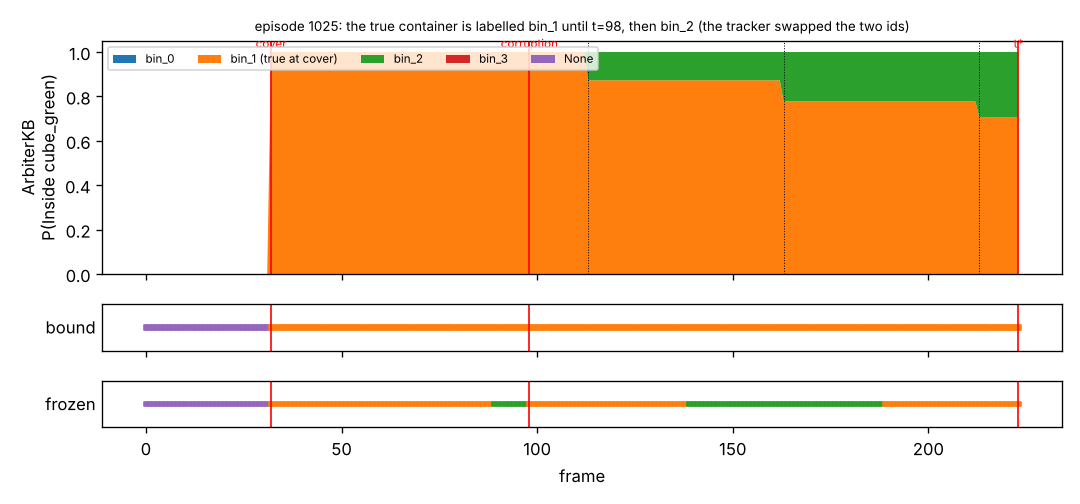

In [9]:
# Summary figure from the full run (make selftest writes it)
from IPython.display import Image
Image('../figures/m0_belief_timeline_synthetic_p1.0.png')